# Exact HD plateau reconstruction

This notebook takes the NPZ files written by `hd_full_matrix_snr.py`, finds the points where the MINRES
value of $\rho_{\rm HD}$ is accurate, and replaces the points that are not with an exact solution.

**Exact solver.** The HD SNR is $\rho^2_{\rm HD} = 2\,F_{ab}^T (M')^{-1} F_{ab}$, where
$M'_{ab,cd} = \tilde P_{ac}\tilde P_{bd} + \tilde P_{ad}\tilde P_{bc}$ acts on the $N(N-1)/2$ pairs.
Applying $M'$ to a pair vector $z$ is $Z \mapsto (\tilde P Z \tilde P)_{a<b}$ with $Z$ symmetric and zero on the diagonal.
On the full space of symmetric matrices that map has the exact inverse $Z \mapsto Q Z Q$ with $Q = \tilde P^{-1}$.
Removing the $N$ diagonal (auto-correlation) entries with a Schur complement gives

$$\rho^2_{\rm HD} = \mathrm{tr}(F Q F Q) - u^T (Q\circ Q)^{-1} u, \qquad u = \mathrm{diag}(Q F Q).$$

Every step is an $N\times N$ operation, so the cost is about one second per value of $P_{\rm gw}/P_n$ at $N=1000$,
with no tolerance, warm start, or grid dependence. One step of iterative refinement is applied and the
relative residual of the pair system is reported for every point.

**Trust rule.** Starting from the largest $P_{\rm gw}/P_n$ and moving down, the exact value is computed and compared
with the NPZ value. Once `N_CONSEC` consecutive points agree to `RTOL`, everything below is kept from the NPZ.
Every point above that run is replaced by the exact value. CP is already exact in the pipeline and is not changed.

In [ ]:
import os, sys, time, glob
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from scipy.linalg import lu_factor, lu_solve

# ---- user settings -------------------------------------------------------
CODE_DIR  = "."            # folder containing main.py and hd_full_matrix_snr.py
NPZ_FILES = sorted(glob.glob("hd_full_matrix_snr_N*_FoV*_normGamma.npz"))
OUT_SUFFIX = "_exact"      # output: <input stem>_exact.npz (inputs are never modified)
RTOL      = 1e-4           # NPZ and exact agree if |rho_npz/rho_exact - 1| <= RTOL
N_CONSEC  = 5              # consecutive agreeing points needed before the scan stops
RES_TOL   = 1e-8           # exact points with a larger relative residual are flagged
GAMMA_GRID = 6000          # angular grid points used to build Gamma (see section 2)
PLOT_R_MIN = 1e-14         # x-axis limits of the plot
PLOT_R_MAX = 1e4
EXTEND_CURVES = False      # False: curves stop at the run's grid, leaving margins on the axis
                           # True: curves are filled out to the axis limits with exact values (plot only)
# --------------------------------------------------------------------------

sys.path.insert(0, os.path.abspath(CODE_DIR))
import main as M
import hd_full_matrix_snr as H
%matplotlib inline
print("NORMALIZED_GAMMA =", M.NORMALIZED_GAMMA, "| gamma_scale_factor =", M.gamma_scale_factor())
print("files:", *NPZ_FILES, sep="\n  ")

NORMALIZED_GAMMA = True | gamma_scale_factor = 1.0
files:
  hd_full_matrix_snr_N1000_FoV10_normGamma.npz
  hd_full_matrix_snr_N1000_FoV45.8_normGamma.npz


## 1. Exact HD solver

`hd_exact` uses the same convention as `hd_full_matrix_snr.py`: cross-power $F\Gamma_{ab}$, auto-power
$1/r + F\Gamma(0)$, right-hand side $F\Gamma_{ab}$, all with $F$ = `gamma_scale_factor()`.
The eigendecomposition of $F\Gamma$ is done once per field, so each new value of $r$ needs only
matrix products and one $N\times N$ LU solve.

In [ ]:
class HDExact:
    def __init__(self, gamma_matrix, gamma0):
        F = M.gamma_scale_factor()
        self.Fm = F * np.array(gamma_matrix, float)
        np.fill_diagonal(self.Fm, 0.0)
        self.p0 = F * float(gamma0)
        N = self.Fm.shape[0]
        self.mu, self.V = np.linalg.eigh(self.Fm + self.p0 * np.eye(N))   # P(r) = V diag(mu + 1/r) V^T
        self.iu = np.triu_indices(N, 1)

    def _setup(self, r):
        q = 1.0 / (self.mu + 1.0 / r)
        self.Q = (self.V * q) @ self.V.T
        self.P = (self.V * (self.mu + 1.0 / r)) @ self.V.T
        self.S_lu = lu_factor(self.Q * self.Q)

    def _apply_inverse(self, B):
        # pair-space inverse of M' applied to the off-diagonal symmetric matrix B
        W = self.Q @ B @ self.Q
        d = lu_solve(self.S_lu, np.diag(W).copy())
        Z = W - (self.Q * d) @ self.Q
        np.fill_diagonal(Z, 0.0)
        return Z

    def _residual(self, Z):
        R = self.P @ Z @ self.P - self.Fm
        np.fill_diagonal(R, 0.0)
        return R

    def __call__(self, r):
        # returns (rho_HD, relative residual of the pair system after one refinement step)
        self._setup(r)
        Z = self._apply_inverse(self.Fm)
        Z = Z - self._apply_inverse(self._residual(Z))          # iterative refinement
        R = self._residual(Z)
        rel = np.linalg.norm(R[self.iu]) / np.linalg.norm(self.Fm[self.iu])
        rho2 = np.sum(self.Fm[self.iu] * Z[self.iu]) * 2.0
        return np.sqrt(max(rho2, 0.0)), rel

**Self-test.** At small $N$ the full pair covariance fits in memory, so `hd_exact` is checked against the pipeline's
dense solve `rho_hd_weighted_dense` over the full range of $r$.

In [ ]:
_s = M.build_star_positions(None, 25, 10.0, M.RANDOM_SEED)
_th = M.pairwise_theta(_s); _lmin, _lmax = M.compute_ell_limits(_th, 10.0)
_G = M.gamma_parallel_matrix(_th, _lmin, _lmax); _g0 = M.cp_single_star_gamma(_lmin, _lmax)
_r = np.logspace(-12, 3, 16)
_dense = H.rho_hd_weighted_dense(_r, H.build_hd_pair_data(_G, _g0), verbose=False)
_ex = HDExact(_G, _g0)
_fast = np.array([_ex(x)[0] for x in _r])
print(f"N=25 self-test: max |exact/dense - 1| = {np.max(np.abs(_fast/_dense - 1)):.1e}")
assert np.allclose(_fast, _dense, rtol=1e-8), "exact solver disagrees with the dense pipeline solve"

N=25 self-test: max |exact/dense - 1| = 1.7e-10


## 2. Rebuild each field and confirm it matches the NPZ

The star field is rebuilt from `RANDOM_SEED` in `main.py` with the stored $N$ and FoV. Two checks confirm that it is the
same field and the same convention as the run:

1. `ell_max` from the rebuilt field equals the stored `ell_max` (this depends on the closest pair, so it fixes the draw).
2. The weak-signal amplitudes $\rho_{\rm CP}/r$ and $\rho_{\rm HD}/r$ at the first grid point match
   $\sqrt{N/2}\,F\Gamma(0)$ and $\sqrt{2\sum_{a<b}(F\Gamma_{ab})^2}$.

$\Gamma_{ab}$ is evaluated by `gamma_parallel` on a fine angular grid with the run's `ell_min` and `ell_max`, then
interpolated to every pair with a cubic spline. Evaluating all $N(N-1)/2$ pairs through the Legendre recurrence takes
about an hour at $N=1000$. The spline is checked against direct `gamma_parallel` calls on a random subset of pairs and on
the closest pairs; the difference is at the $10^{-8}$ level, which is the round-off of the recurrence itself.

In [ ]:
def rebuild_field(d):
    N, fov = int(d["N_STARS"]), float(d["FIELD_SIZE_DEG"])
    stars = M.build_star_positions(None, N, fov, M.RANDOM_SEED)
    th = M.pairwise_theta(stars)
    lmin, lmax = M.compute_ell_limits(th, fov)
    assert lmax == int(d["ell_max"]), f"ell_max {lmax} != stored {int(d['ell_max'])}: not the same star field"
    iu = np.triu_indices(N, 1); tp = th[iu]
    grid = np.concatenate([[0.0], np.geomspace(0.5 * tp.min(), 1.001 * tp.max(), GAMMA_GRID)])
    spl = CubicSpline(grid, M.gamma_parallel(grid, lmin, lmax))
    G = spl(np.nan_to_num(th, nan=0.0)); np.fill_diagonal(G, np.nan)
    # spline check against the pipeline's own Gamma
    k = np.r_[np.random.default_rng(0).choice(tp.size, 200, replace=False), np.argsort(tp)[:20]]
    err = np.max(np.abs(G[iu][k] - M.gamma_parallel(tp[k], lmin, lmax)))
    assert err < 1e-6, f"Gamma interpolation error {err:.1e} too large; increase GAMMA_GRID"
    return G, M.cp_single_star_gamma(lmin, lmax), lmin, lmax, err

def check_weak(d, G, g0):
    F = M.gamma_scale_factor(); N = G.shape[0]
    r0 = d["r_vals"][0]
    cp_exp = np.sqrt(N / 2.0) * F * g0
    hd_exp = np.sqrt(2.0 * np.sum((F * G[np.triu_indices(N, 1)]) ** 2))
    e_cp = d["rho_cp"][0] / r0 / cp_exp - 1
    e_hd = d["rho_hd"][0] / r0 / hd_exp - 1
    print(f"  weak-signal CP amplitude: file/expected - 1 = {e_cp:+.1e}")
    print(f"  weak-signal HD amplitude: file/expected - 1 = {e_hd:+.1e}")
    assert abs(e_hd) < 1e-3 and abs(e_cp) < 1e-3, "weak-signal amplitudes do not match: NPZ was made with a different convention"

## 3. Find the trustworthy points and replace the rest

In [ ]:
def reconstruct(path):
    d = dict(np.load(path))
    r, rho_npz = d["r_vals"], d["rho_hd"]
    print(f"\n{os.path.basename(path)}: N={int(d['N_STARS'])}, FoV={float(d['FIELD_SIZE_DEG']):g} deg, {r.size} points")
    t0 = time.time()
    G, g0, lmin, lmax, gerr = rebuild_field(d)
    print(f"  field rebuilt, ell_max={lmax} matches, Gamma spline error {gerr:.1e} ({time.time()-t0:.0f}s)")
    check_weak(d, G, g0)

    solver = HDExact(G, g0)
    exact = np.full(r.size, np.nan); res = np.full(r.size, np.nan)
    run = 0; t0 = time.time()
    for i in range(r.size - 1, -1, -1):                       # largest r first
        exact[i], res[i] = solver(r[i])
        run = run + 1 if abs(rho_npz[i] / exact[i] - 1) <= RTOL else 0
        if run == N_CONSEC:
            break
    else:
        raise RuntimeError("NPZ never agreed with the exact solution; check RTOL and the convention")
    keep_to = i + N_CONSEC - 1                                # last index of the agreeing run
    replaced = np.zeros(r.size, bool); replaced[keep_to + 1:] = True
    print(f"  {np.sum(~np.isnan(exact))} exact solves in {time.time()-t0:.0f}s")
    print(f"  NPZ trusted for r <= {r[keep_to]:.2e} ({keep_to+1} points); replaced {replaced.sum()} points above")
    flag = replaced & (res > RES_TOL)
    if flag.any():
        print(f"  WARNING: {flag.sum()} replaced points have residual > {RES_TOL:g} (r >= {r[flag].min():.2e}); treat as approximate")
    else:
        print(f"  all replaced points have residual <= {RES_TOL:g} (max {np.nanmax(res[replaced]) if replaced.any() else 0:.1e})")

    rho_final = rho_npz.copy(); rho_final[replaced] = exact[replaced]
    out = dict(d); out["rho_hd"] = rho_final
    out["HD_EXACT_ABOVE_R"] = r[keep_to]                      # points with r > this value are exact
    stem, _ = os.path.splitext(path)
    np.savez(stem + OUT_SUFFIX + ".npz", **out)
    print(f"  saved {os.path.basename(stem + OUT_SUFFIX + '.npz')}")
    # exact extension beyond the NPZ grid, for the plot only (same points per decade)
    step = np.log10(r[1] / r[0])
    r_lo = 10**np.arange(np.log10(r[0]) - step, np.log10(PLOT_R_MIN) - 1e-9, -step)[::-1]
    r_hi = 10**np.arange(np.log10(r[-1]) + step, np.log10(PLOT_R_MAX) + 1e-9, step)
    r_ext = np.r_[r_lo, r_hi] if EXTEND_CURVES else np.array([])
    hd_ext, res_ext = (np.array(v) for v in zip(*[solver(x) for x in r_ext])) if r_ext.size else (np.array([]), np.array([]))
    cp_ext = M.rho_cp_full(r_ext, G, lmin, lmax, verbose=False) if r_ext.size else np.array([])
    if r_ext.size:
        print(f"  plot extended to [{PLOT_R_MIN:.0e}, {PLOT_R_MAX:.0e}] with {r_ext.size} exact points; "
              f"max residual {np.max(res_ext):.1e}" + ("  (above RES_TOL: lower PLOT_R_MAX)" if np.max(res_ext) > RES_TOL else ""))
    order = np.argsort(np.r_[r, r_ext])
    r_plot = np.r_[r, r_ext][order]
    cp_plot = np.r_[d["rho_cp"], cp_ext][order]
    hd_plot = np.r_[rho_final, hd_ext][order]
    return dict(d=d, r=r, rho_npz=rho_npz, exact=exact, res=res, replaced=replaced,
                keep_to=keep_to, rho_final=rho_final, flag=flag,
                r_plot=r_plot, cp_plot=cp_plot, hd_plot=hd_plot)

results = {p: reconstruct(p) for p in NPZ_FILES}


hd_full_matrix_snr_N1000_FoV10_normGamma.npz: N=1000, FoV=10 deg, 161 points
  field rebuilt, ell_max=349354 matches, Gamma spline error 1.6e-08 (57s)
  weak-signal CP amplitude: file/expected - 1 = -4.9e-14
  weak-signal HD amplitude: file/expected - 1 = -9.9e-11
  23 exact solves in 3s
  NPZ trusted for r <= 1.58e+01 (143 points); replaced 18 points above
  all replaced points have residual <= 1e-08 (max 3.0e-13)
  saved hd_full_matrix_snr_N1000_FoV10_normGamma_exact.npz

hd_full_matrix_snr_N1000_FoV45.8_normGamma.npz: N=1000, FoV=45.8 deg, 161 points
  field rebuilt, ell_max=77900 matches, Gamma spline error 3.5e-09 (13s)
  weak-signal CP amplitude: file/expected - 1 = -4.9e-14
  weak-signal HD amplitude: file/expected - 1 = -7.5e-11
  26 exact solves in 4s
  NPZ trusted for r <= 7.94e+00 (140 points); replaced 21 points above
  all replaced points have residual <= 1e-08 (max 6.1e-13)
  saved hd_full_matrix_snr_N1000_FoV45.8_normGamma_exact.npz


## 4. Plot

Same figure as `plot_full_comparison` in `hd_full_matrix_snr.py`, drawn from the reconstructed curves.
The axis spans `[PLOT_R_MIN, PLOT_R_MAX]`. With `EXTEND_CURVES = True` the curves are filled out to those limits with exact CP and HD values; otherwise they stop at the run's grid.
Each figure is also saved as `<input stem>_exact.png`.

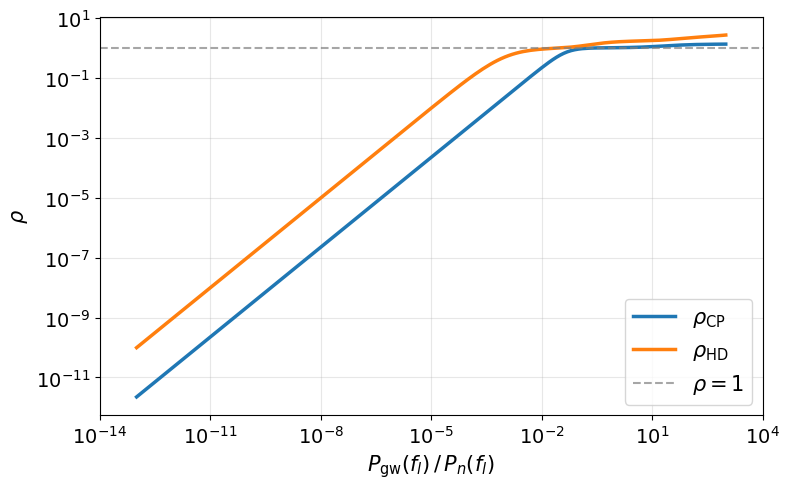

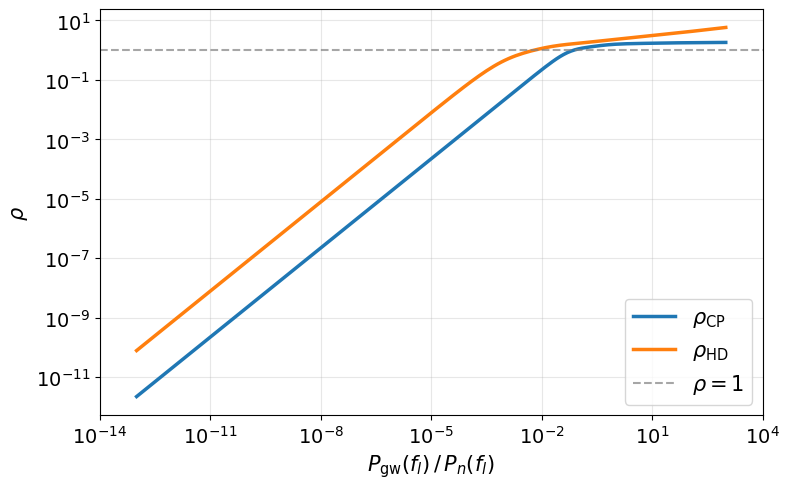

In [ ]:
MISSION = {10.0: "Kepler", 45.8: "PLATO"}       # FoV (deg) -> mission name for titles

for p, R in results.items():
    d, r = R["d"], R["r"]
    fov = float(d["FIELD_SIZE_DEG"])
    mission = MISSION.get(round(fov, 1), f"FoV {fov:g}°")
    phys = float(d["PHYSICAL_RATIO"])

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.loglog(R["r_plot"], R["cp_plot"], color="C0", lw=2.5, label=r"$\rho_{\rm CP}$")
    ax.loglog(R["r_plot"], R["hd_plot"], color="C1", lw=2.5, label=r"$\rho_{\rm HD}$")
    ax.axhline(y=1, color="gray", linestyle="--", lw=1.5, alpha=0.7, label=r"$\rho=1$")

    ax.set_xlim(PLOT_R_MIN, PLOT_R_MAX)
    ax.set_xlabel(r"$P_{\rm gw}(f_l)\,/\,P_n(f_l)$", fontsize=15)
    ax.set_ylabel(r"$\rho$", fontsize=15)
    ax.legend(fontsize=15)
    ax.grid(True, which="both", alpha=0.3)
    ax.tick_params(axis="both", which="major", labelsize=14)
    plt.tight_layout()
    stem, _ = os.path.splitext(p)
    plt.savefig(stem + OUT_SUFFIX + ".png", dpi=150)
    plt.show()